# Задание
1. Обучить модель с использованием метода опорных векторов. 
2. Подобрать гиперпараметры модели, позволяющие минимизировать величину roc_auc. 
3. Сравнить с результатами, полученными по лучшей модели логистической регрессии.

In [16]:
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objs as go
from plotly.subplots import make_subplots

from sklearn import datasets, svm
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.feature_selection import SelectKBest, f_classif, SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, 
    brier_score_loss, 
    classification_report, 
    confusion_matrix, 
    ConfusionMatrixDisplay, 
    roc_auc_score, 
    RocCurveDisplay
)
from sklearn.model_selection import (
    cross_val_score, 
    GridSearchCV, 
    StratifiedKFold, 
    train_test_split
)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

In [2]:
df = pd.read_excel('orders_short_v3.xlsx')

In [3]:
df = df.drop('Unnamed: 0', axis='columns')

In [4]:
df.drop(['Идентификатор погрузки',
         'Дата редактирования', 
         'Дата отправления', 
         'Дата отправления факт', 
         'Количество редакций после отправки',
         'Длительность афтершока', 
         'Код назначения', 
         'Код отправления', 
         'Идентификатор переноса'], axis = 1, inplace = True)
cat = [
    'Оператор', 
    'Учетное направление', 
    'Кластер назначения', 
    'Кластер отправления']
numerical = [
    'версия погрузки',
    'Количество вагонов',
    'Контрибуция',
    'Длительность жизни',
    'Время до отправки',
    'Количество отмен',
    'Количество переносов',
    'Среднее время между редакциями']
target = 'Результат'

In [5]:
# кодирование
df_encoded = pd.get_dummies(df, columns=cat, drop_first=True)
# отделение признаков от целевой переменной
X = df_encoded.drop(columns=[target])
y = df_encoded[target]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [7]:
#стандартизация (делаем стандартскалером, т.к. в прошыле разы на этих данных он показал лучшие результаты)
sc = StandardScaler()
X_train[numerical] = sc.fit_transform(X_train[numerical])
X_test[numerical] = sc.transform(X_test[numerical])
feature_names = X.columns.tolist()

In [8]:
model_isotonic = CalibratedClassifierCV(LinearSVC(random_state=42),  method='isotonic', cv=5)

In [9]:
#последовательный отбор
k_features = 36
sfs = SequentialFeatureSelector(
    estimator=model_isotonic,
    n_features_to_select=k_features,
    direction='forward',
    cv=3,
    scoring='roc_auc',
    n_jobs=-1
)

start_time = time.time()
sfs.fit(X_train, y_train)
print(f"Время работы SFS: {time.time() - start_time:.2f} сек.")

X_train_sfs = sfs.transform(X_train)
X_test_sfs = sfs.transform(X_test)

selected_sfs = [feature_names[i] for i in sfs.get_support(indices=True)]
print(f"\nОтобранные признаки ({k_features} шт.):")
for name in selected_sfs:
    print(f"  - {name}")

start_time = time.time()
sfs_scores = cross_val_score(model_isotonic, X_train_sfs, y_train, cv=5, scoring='roc_auc')
print(f"\nСредний ROC-AUC (CV=5): {sfs_scores.mean():.4f} ± {sfs_scores.std():.4f}")
print(f"Время оценки: {time.time() - start_time:.2f} сек.")

Время работы SFS: 487.01 сек.

Отобранные признаки (36 шт.):
  - версия погрузки
  - Длительность жизни
  - Время до отправки
  - Количество отмен
  - Количество переносов
  - Среднее время между редакциями
  - Оператор_Belyaevaev
  - Оператор_Chernokozinskiyln
  - Оператор_Cimermanea
  - Оператор_Devaevrd
  - Оператор_Harinva
  - Оператор_Jeleznayatn
  - Оператор_Kivimyagiaa
  - Оператор_Matyushenkoav
  - Оператор_Rodkevicha
  - Оператор_Rulskiya
  - Оператор_Samoylovichoa
  - Оператор_Suhovayv
  - Оператор_Tsaplikmv
  - Оператор_Vasilevnd
  - Учетное направление_(8) ВРП
  - Учетное направление_(93) Досыл из под ПВ
  - Кластер назначения_65270
  - Кластер назначения_80250
  - Кластер назначения_90230
  - Кластер назначения_АЗР
  - Кластер назначения_ВСБ
  - Кластер назначения_КЗХ
  - Кластер назначения_КРС
  - Кластер назначения_МСК
  - Кластер назначения_СПб
  - Кластер отправления_АЗР
  - Кластер отправления_МСК
  - Кластер отправления_Монголия
  - Кластер отправления_УЗБ
  - Класте

In [10]:
param_grid = [
    # Линейное ядро
    {'kernel': ['linear'],
     'C': [0.01, 0.1, 1, 10, 100]},
    # Гауссово ядро
    {'kernel': ['rbf'],
     'C': [0.1, 1, 10, 100],
     'gamma': ['scale', 'auto', 0.001, 0.01, 0.1],
     'class_weight': [None, 'balanced']},
    # Полиномиальное ядро
    {'kernel': ['poly'],
     'C': [0.1, 1, 10], 
     'gamma': ['scale', 'auto', 0.01],
     'degree': [2, 3, 4],
     'coef0': [0, 1]}]
cv = StratifiedKFold(shuffle=True, n_splits=5, random_state=42)

In [11]:
SVM_GS = GridSearchCV(
    estimator=svm.SVC(random_state=42, probability=True),
    param_grid=param_grid,
    scoring='roc_auc',    
    cv=cv,                  
    n_jobs=-1,              
    verbose=2,              
    return_train_score=True)
SVM_GS.fit(X_train[selected_sfs], y_train)

Fitting 5 folds for each of 99 candidates, totalling 495 fits


,estimator,SVC(probabili...ndom_state=42)
,param_grid,"[{'C': [0.01, 0.1, ...], 'kernel': ['linear']}, {'C': [0.1, 1, ...], 'class_weight': [None, 'balanced'], 'gamma': ['scale', 'auto', ...], 'kernel': ['rbf']}, ...]"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,C,100


In [12]:
#выводим лучшие параметры
print(SVM_GS.best_params_)
print(SVM_GS.best_score_)
print(SVM_GS.best_estimator_)

{'C': 100, 'class_weight': 'balanced', 'gamma': 0.01, 'kernel': 'rbf'}
0.8711830032671342
SVC(C=100, class_weight='balanced', gamma=0.01, probability=True,
    random_state=42)


In [13]:
#находим вероятности
train_probst = SVM_GS.predict_proba(X_train[selected_sfs])[:, 1]
test_probst = SVM_GS.predict_proba(X_test[selected_sfs])[:, 1]
#предсказания
train_predst = SVM_GS.predict(X_train[selected_sfs])
test_predst = SVM_GS.predict(X_test[selected_sfs])

## качество модели на трейне

In [14]:
print(f"Accuracy: {accuracy_score(y_train, train_predst):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_train, train_probst):.4f}")
print(classification_report(y_train, train_predst, target_names=['Класс 0', 'Класс 1']))

Accuracy: 0.8174
ROC-AUC:  0.8913
              precision    recall  f1-score   support

     Класс 0       0.75      0.86      0.80      1090
     Класс 1       0.88      0.79      0.83      1462

    accuracy                           0.82      2552
   macro avg       0.82      0.82      0.82      2552
weighted avg       0.83      0.82      0.82      2552



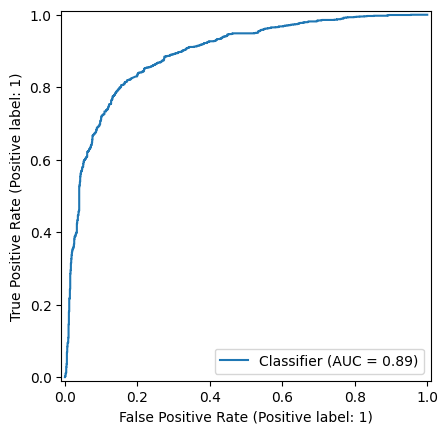

In [17]:
RocCurveDisplay.from_predictions(y_train, train_probst)

## качество модели на тесте

In [18]:
print(f"Accuracy: {accuracy_score(y_test, test_predst):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, test_probst):.4f}")
print(classification_report(y_test, test_predst, target_names=['Класс 0', 'Класс 1']))

Accuracy: 0.7947
ROC-AUC:  0.8759
              precision    recall  f1-score   support

     Класс 0       0.72      0.86      0.78       273
     Класс 1       0.88      0.74      0.81       365

    accuracy                           0.79       638
   macro avg       0.80      0.80      0.79       638
weighted avg       0.81      0.79      0.80       638



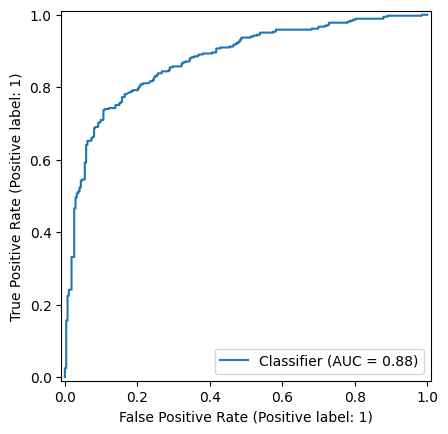

In [19]:
RocCurveDisplay.from_predictions(y_test, test_probst)

## Лучшая модель лог регрессии

In [8]:
#последовательный отбор
k_features = 36
sfs = SequentialFeatureSelector(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    n_features_to_select=k_features,
    direction='forward',
    cv=3,
    scoring='roc_auc',
    n_jobs=-1
)

start_time = time.time()
sfs.fit(X_train, y_train)
print(f"Время работы SFS: {time.time() - start_time:.2f} сек.")

X_train_sfs = sfs.transform(X_train)
X_test_sfs = sfs.transform(X_test)

selected_sfs = [feature_names[i] for i in sfs.get_support(indices=True)]
print(f"\nОтобранные признаки ({k_features} шт.):")
for name in selected_sfs:
    print(f"  - {name}")

model_sfs = LogisticRegression(max_iter=1000, random_state=42)
start_time = time.time()
sfs_scores = cross_val_score(model_sfs, X_train_sfs, y_train, cv=5, scoring='roc_auc')
print(f"\nСредний ROC-AUC (CV=5): {sfs_scores.mean():.4f} ± {sfs_scores.std():.4f}")
print(f"Время оценки: {time.time() - start_time:.2f} сек.")

Время работы SFS: 76.32 сек.

Отобранные признаки (36 шт.):
  - версия погрузки
  - Длительность жизни
  - Время до отправки
  - Количество отмен
  - Количество переносов
  - Среднее время между редакциями
  - Оператор_Belyaevaev
  - Оператор_Gruzdevao
  - Оператор_Jeleznayatn
  - Оператор_Kivimyagiaa
  - Оператор_Kuznecovaea
  - Оператор_Matyushenkoav
  - Оператор_Pahomovayv
  - Оператор_Rulskiya
  - Оператор_Samoylovichoa
  - Оператор_Suhovayv
  - Оператор_Tsaplikmv
  - Оператор_Vasilevnd
  - Учетное направление_(8) ВРП
  - Учетное направление_(9) Подсыл порожних КТК
  - Учетное направление_(93) Досыл из под ПВ
  - Кластер назначения_65270
  - Кластер назначения_АЗР
  - Кластер назначения_БЕЛ
  - Кластер назначения_ВСБ
  - Кластер назначения_Европа
  - Кластер назначения_КЗХ
  - Кластер назначения_КРС
  - Кластер назначения_МСК
  - Кластер назначения_Якутия
  - Кластер отправления_АЗР
  - Кластер отправления_ЗБК
  - Кластер отправления_КРС
  - Кластер отправления_Монголия
  - Кластер

In [11]:
modelLogReg = LogisticRegression(random_state=42, max_iter=2000)

params = [ # берем два словаря для подбора из-за несовместимости штрафа и солвера
    {'penalty': ['l1', 'l2'],
     'C': [0.001, 0.01, 0.1, 1, 10, 100],
     'solver': ['liblinear', 'saga']},
    {'penalty': ['elasticnet'],
     'C': [0.001, 0.01, 0.1, 1, 10, 100],
     'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
     'solver': ['saga']}]

cv = StratifiedKFold(shuffle=True, n_splits=5, random_state=42)

GS_LogReg = GridSearchCV(
    estimator=modelLogReg, 
    param_grid=params, 
    cv=cv, 
    scoring='roc_auc',
    verbose=1,  
    n_jobs=-1,  
    refit=True,
) 

GS_LogReg.fit(X_train[selected_sfs], y_train)

Fitting 5 folds for each of 54 candidates, totalling 270 fits


,estimator,LogisticRegre...ndom_state=42)
,param_grid,"[{'C': [0.001, 0.01, ...], 'penalty': ['l1', 'l2'], 'solver': ['liblinear', 'saga']}, {'C': [0.001, 0.01, ...], 'l1_ratio': [0.1, 0.3, ...], 'penalty': ['elasticnet'], 'solver': ['saga']}]"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l1'


In [12]:
#выводим лучшие параметры
print(GS_LogReg.best_params_)
print(GS_LogReg.best_score_)
print(GS_LogReg.best_estimator_)

{'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}
0.8619774333115581
LogisticRegression(C=10, max_iter=2000, penalty='l1', random_state=42,
                   solver='liblinear')


In [13]:
#находим вероятности
train_probst = GS_LogReg.predict_proba(X_train[selected_sfs])[:, 1]
test_probst = GS_LogReg.predict_proba(X_test[selected_sfs])[:, 1]
#предсказания
train_predst = GS_LogReg.predict(X_train[selected_sfs])
test_predst = GS_LogReg.predict(X_test[selected_sfs])

## качество модели на тесте

In [14]:
print(f"Accuracy: {accuracy_score(y_test, test_predst):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, test_probst):.4f}")
print(classification_report(y_test, test_predst, target_names=['Класс 0', 'Класс 1']))

Accuracy: 0.7884
ROC-AUC:  0.8657
              precision    recall  f1-score   support

     Класс 0       0.75      0.75      0.75       273
     Класс 1       0.82      0.81      0.81       365

    accuracy                           0.79       638
   macro avg       0.78      0.78      0.78       638
weighted avg       0.79      0.79      0.79       638



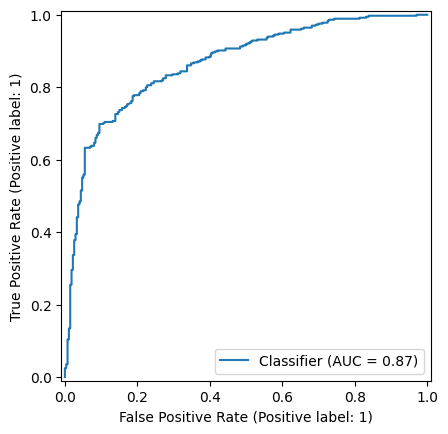

In [15]:
RocCurveDisplay.from_predictions(y_test, test_probst)

## сравнение моделей

РОК АУК лог регрессии на тесте:
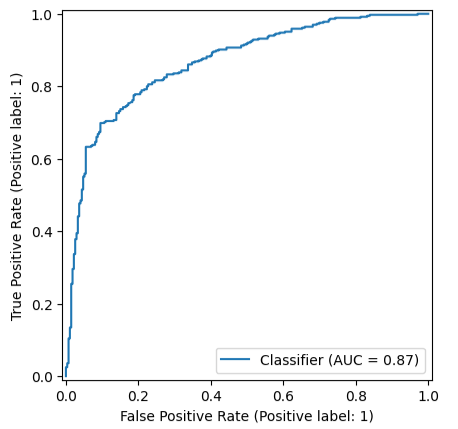 

РОК АУК метода опорных векторов на тесте:
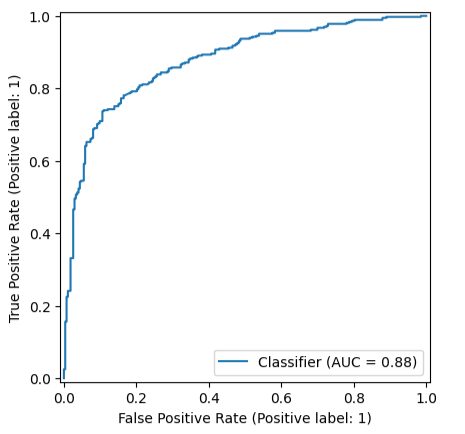

В целом результаты получились очень похожими, разница в качестве моделей незначительная, что в целом не уидивтельно ведь оба метода являются линейными